In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


Setting Parameters

In [2]:
S0 = 100    # underlying asset at t = 0 in $
r = 0.02    # risk free interest rate
sigma = 0.3 # volatility
T = 1       # maturity in year
N = 100     # number of points
dt = T/N
nb_simulation = 1000

Simulation of underlying asset paths

In [3]:
S = np.zeros((nb_simulation,N))
S[:,0]=S0
for t in range(1,N):
    Z = np.random.normal(0,1,nb_simulation)
    S[:,t] = S[:,t-1]*np.exp((r-0.5*sigma**2)*dt+sigma*np.sqrt(dt)*Z)

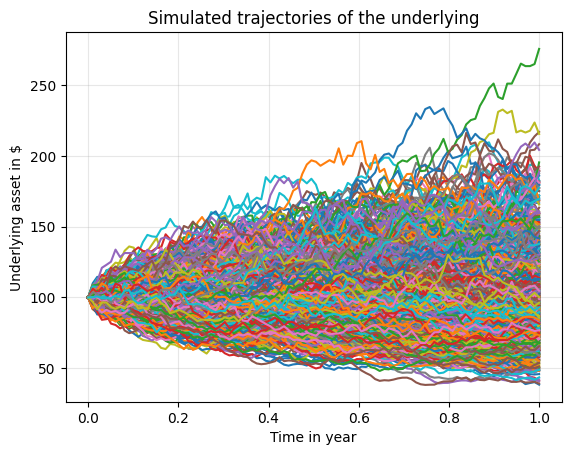

In [4]:
Time = np.linspace(0,1,N)
for s in S:
    plt.plot(Time,s)
plt.xlabel("Time in year")
plt.ylabel("Underlying asset in $")
plt.title("Simulated trajectories of the underlying")
plt.grid(True, alpha=0.3)
plt.show()

In [5]:
S

array([[100.        , 103.19476893,  98.33504271, ..., 101.7483557 ,
        100.74138876, 108.70647203],
       [100.        , 101.63393363, 102.73976948, ...,  71.80236098,
         72.80879185,  74.14080731],
       [100.        ,  97.5471835 ,  97.48604228, ...,  66.96983826,
         67.72241512,  64.21878057],
       ...,
       [100.        , 103.77202776, 102.49581694, ..., 134.15907359,
        131.20841839, 127.76074811],
       [100.        ,  96.91068618,  91.71251386, ..., 100.50530339,
        103.32719408, 100.24243267],
       [100.        , 100.19938233, 100.7373136 , ...,  93.72412966,
         90.79714894,  93.08403546]], shape=(1000, 100))

European Call pricing with the Montecarlo method

In [6]:
K = 100         # Strike in $
ST = S[:,-1]    # Values of the underlying in $ at t = T

payoff = np.maximum(ST-K,0)

call_price = np.mean(payoff) * np.exp(-r*T)
print(f"The call price at t=0 is {round(call_price,5)} $")

The call price at t=0 is 12.297 $


Call Up & Out Pricing

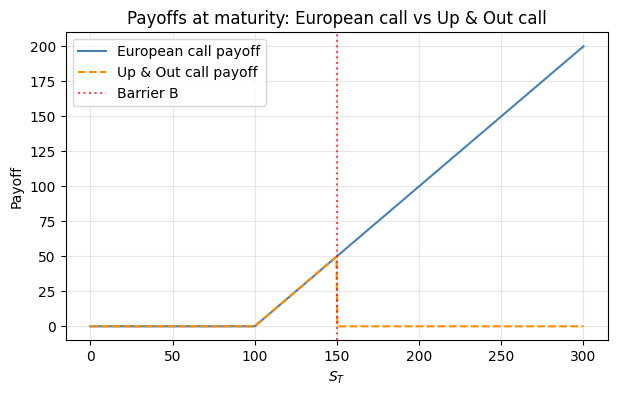

In [7]:
K = 100     # strike
B = 150     # barrier

# grid
ST_grid = np.linspace(0, 2*B, 500)

# European call payoff
payoff_call = np.maximum(ST_grid - K, 0)

# Call Up&Out payoff
payoff_uo = np.where(ST_grid < B, payoff_call, 0.0)

plt.figure(figsize=(7,4))

plt.plot(ST_grid, payoff_call, label="European call payoff", color="steelblue")
plt.plot(ST_grid, payoff_uo,   label="Up & Out call payoff", color="darkorange", linestyle="--")

plt.axvline(B, color="red",  linestyle=":", alpha=0.7, label="Barrier B")

plt.xlabel("$S_T$")
plt.ylabel("Payoff")
plt.title("Payoffs at maturity: European call vs Up & Out call")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


In [8]:
# Parameters

# same as before: strike, risk free rate, volatility

B = 150     # Barrier in $

# if the underlying is above B at any time before T, the option is deactivated
L = []
for s in S:
    if max(s)<B:
            L.append(s)

L = np.array(L)
payoff = np.maximum(L[:,-1]-K,0)
print(payoff)

[ 8.70647203  0.          0.          0.          0.         23.04590872
 13.08640579 21.86429784  9.86595418  0.          3.04075212  0.
  0.         19.96740848  0.          0.          0.          0.
  0.          0.          0.         13.82545189  7.11793623 29.53426781
  0.75509809  1.53714216  0.          0.          2.11583688  0.62440793
 16.11427652  0.          0.          0.          0.          0.
  0.          0.          0.          8.405293    0.          0.
  0.          0.          0.          0.          0.          0.
 18.45692083  0.          0.         21.47434175  0.          0.
 34.19542221  0.          0.          0.         17.22164381  0.
 37.27745124  0.          0.          0.          0.88718105  3.96255959
 40.7414165   0.         31.17441743 10.11103984  0.          0.
  0.         10.7148966   0.         27.58895695  0.         19.71915221
  0.          0.         27.58601602  0.          1.22926719  0.
  0.          0.          0.          0.          

In [ ]:
UO_price = np.mean(payoff)*np.exp(-r*T)
print(f"The Call Up & Out price at t=0 is {round(UO_price,5)} $")

The Up & Out call price at t=0 is 5.85332 $


The Call Up & Out is cheaper than the European Call !